In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import xgboost as xgb
# --- display settings ---
# Show up to 20 columns and 100 rows in any DataFrame we print.
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 100)
# Make plots appear inline in the notebook and set a reasonable default size.
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style='whitegrid')
print('All imports successful!')



All imports successful!


In [7]:
df = pd.read_csv('data/AA_PAX_FORECASTING.csv', index_col=0)
df.columns = [c.replace('_', ' ').title() for c in df.columns]
raw = df.copy()
print(df.shape)
df.head()


(1533522, 7)


,Dep Month,Dep Year,Org Airprt,Des Airprt,Od Pax,Od Rev Usd,Sf Load Tms
0,12,2023,SAN,PVR,3609.91,562691.27,2026-09-15 22:06:11.407
1,12,2019,SAN,PVR,3271.89,533964.07,2026-09-15 22:06:11.407
2,8,2022,SAN,PVR,1435.84,167189.61,2026-09-15 22:06:11.407
3,2,2021,SAN,PVR,546.57,80287.17,2026-09-15 22:06:11.407
4,5,2021,SAN,PVR,1741.58,273545.15,2026-09-15 22:06:11.407


In [8]:
df.sample(5)

,Dep Month,Dep Year,Org Airprt,Des Airprt,Od Pax,Od Rev Usd,Sf Load Tms
394889,10,2024,EWR,ATH,8188.49,5880339.86,2026-09-15 22:06:11.407
1515362,1,2024,MYR,CLT,969.99,162514.69,2026-09-15 22:06:11.407
1308647,5,2025,LHR,JFK,86863.11,74912012.59,2026-09-15 22:06:11.407
1245376,7,2021,JFK,MXP,10215.67,5226678.59,2026-09-15 22:06:11.407
233488,10,2025,TUL,TUS,549.69,99224.01,2026-09-15 22:06:11.407


In [9]:
df.dtypes

Dep Month        int64
Dep Year         int64
Org Airprt         str
Des Airprt         str
Od Pax         float64
Od Rev Usd     float64
Sf Load Tms        str
dtype: object

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1533522 entries, 0 to 1533521
Data columns (total 7 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Dep Month    1533522 non-null  int64  
 1   Dep Year     1533522 non-null  int64  
 2   Org Airprt   1533522 non-null  str    
 3   Des Airprt   1533522 non-null  str    
 4   Od Pax       1533522 non-null  float64
 5   Od Rev Usd   1533522 non-null  float64
 6   Sf Load Tms  1533522 non-null  str    
dtypes: float64(2), int64(2), str(3)
memory usage: 124.3 MB


In [11]:
df.describe()

,Dep Month,Dep Year,Od Pax,Od Rev Usd
count,1.533522e+06,1.533522e+06,1.533522e+06,1.533522e+06
mean,6.311087e+00,2.022340e+03,2.765159e+03,6.877597e+05
std,3.440110e+00,2.197267e+00,6.667135e+03,1.880159e+06
min,1.000000e+00,2.019000e+03,1.300000e-01,0.000000e+00
25%,3.000000e+00,2.020000e+03,1.292600e+02,4.642539e+04
50%,6.000000e+00,2.022000e+03,5.026550e+02,1.559138e+05
75%,9.000000e+00,2.024000e+03,2.104030e+03,5.582578e+05
max,1.200000e+01,2.026000e+03,1.401943e+05,1.212712e+08


In [29]:
target = 'Od Pax'

num_cols = df.select_dtypes(include='number').columns.drop(target, errors='ignore').tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print('numeric features:', len(num_cols), '| categorical features:', len(cat_cols))

numeric features: 3 | categorical features: 3


C:\Users\ranga\AppData\Local\Temp\ipykernel_34348\1321575383.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


In [30]:
print(df.isnull().sum())

print(df.isnull().sum() / len(df) * 100)

Dep Month      0
Dep Year       0
Org Airprt     0
Des Airprt     0
Od Pax         0
Od Rev Usd     0
Sf Load Tms    0
dtype: int64
Dep Month      0.0
Dep Year       0.0
Org Airprt     0.0
Des Airprt     0.0
Od Pax         0.0
Od Rev Usd     0.0
Sf Load Tms    0.0
dtype: float64


In [31]:
missing_cols = df.columns[df.isnull().any()].tolist()
print('Columns with missing values:', len(missing_cols))

for m in missing_cols:
    for c in cat_cols:
        if c != m:
            share = df[m].isnull().groupby(df[c]).mean().sort_values(ascending=False)
            print(f'{m} missing by {c}:')
            print((share * 100).round(1).head(10), end='\n\n')

Columns with missing values: 0


In [32]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


In [33]:
df.nunique().sort_values(ascending=False)

Od Rev Usd     1506798
Od Pax          511058
Org Airprt         150
Des Airprt         150
Dep Month           12
Dep Year             8
Sf Load Tms          1
dtype: int64

In [35]:
for col in cat_cols:
    print(df[col].value_counts(dropna=False).head(15), end='\n\n')

Org Airprt
ATL    13326
SEA    13307
DEN    13303
PHX    13297
MSP    13290
PDX    13276
BNA    13276
IND    13255
ORD    13241
MCO    13237
DTW    13225
DFW    13224
BOS    13222
LAS    13218
SLC    13212
Name: count, dtype: int64

Des Airprt
BNA    13467
PIT    13433
IND    13431
MEM    13375
ATL    13349
SEA    13324
DTW    13324
DEN    13323
MSP    13317
SLC    13315
PHX    13314
LAS    13306
CLT    13299
AUS    13294
PDX    13293
Name: count, dtype: int64

Sf Load Tms
2026-09-15 22:06:11.407    1533522
Name: count, dtype: int64



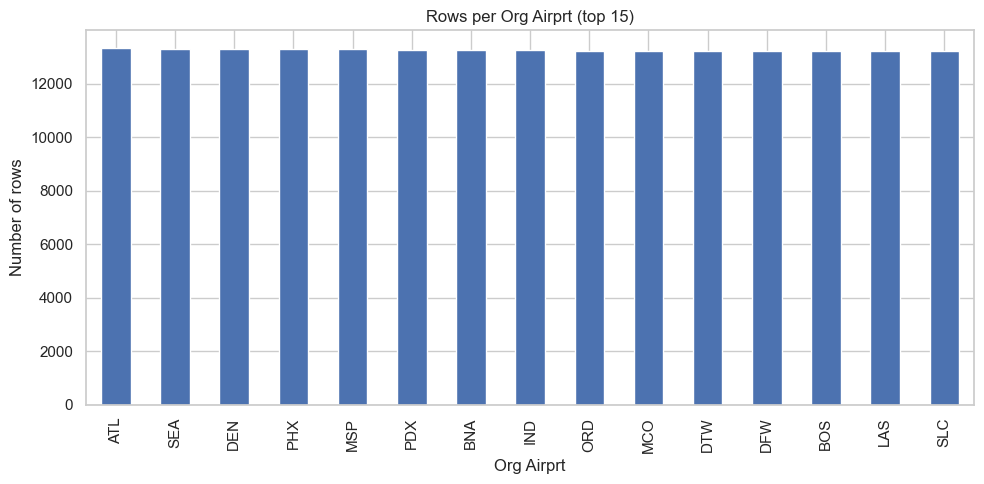

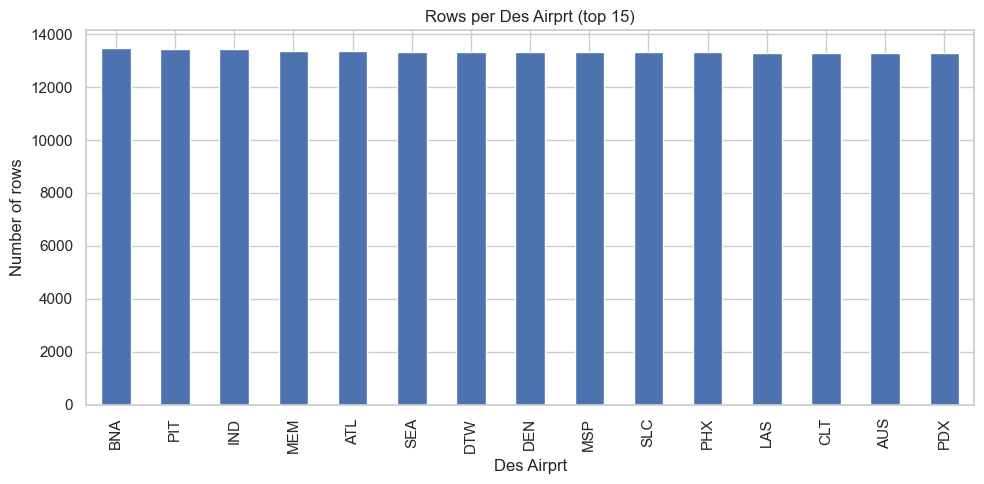

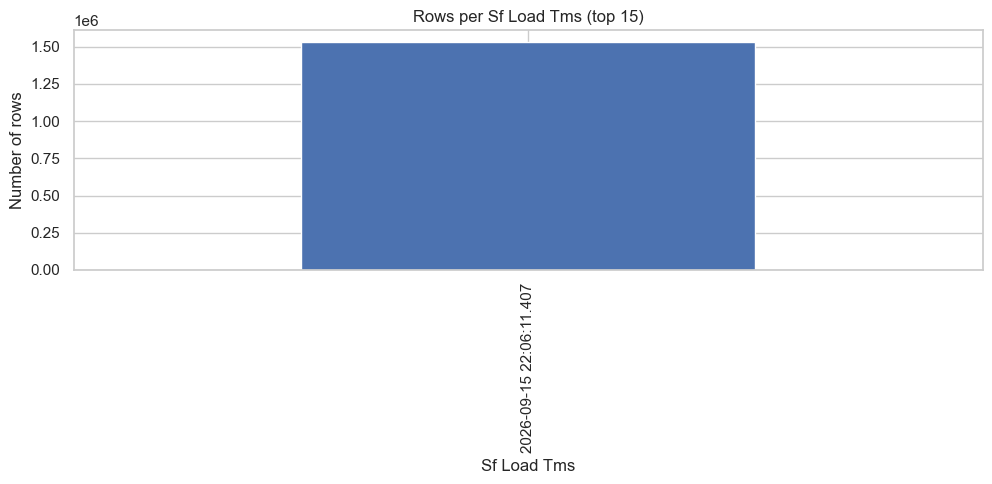

In [36]:
for col in cat_cols:
    df[col].value_counts().head(15).plot(kind='bar')
    plt.title(f'Rows per {col} (top 15)')
    plt.xlabel(col)
    plt.ylabel('Number of rows')
    plt.tight_layout()
    plt.show()

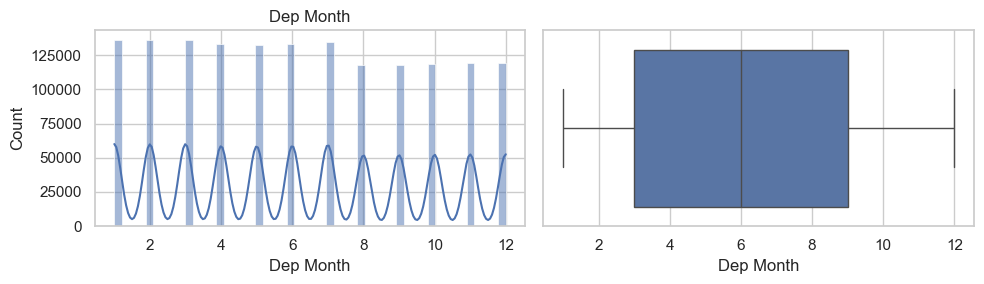

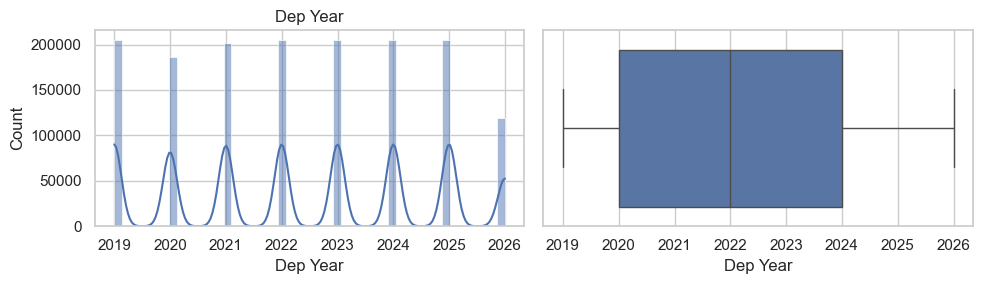

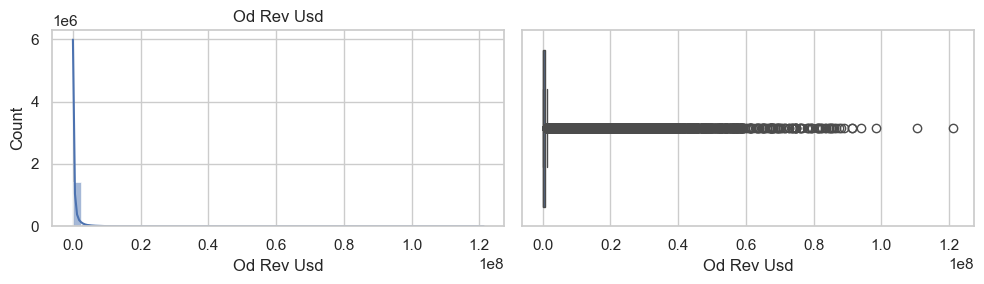

In [37]:
for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(df[col].dropna(), bins=50, kde=True, ax=axes[0])
    sns.boxplot(x=df[col], ax=axes[1])
    axes[0].set_title(col)
    plt.tight_layout()
    plt.show()

In [38]:
df[num_cols + [target]].skew()

Dep Month      0.078510
Dep Year       0.012851
Od Rev Usd    12.056596
Od Pax         5.324332
dtype: float64

In [39]:
values = df[target].dropna().to_numpy()

mean_val   = np.mean(values)
median_val = np.median(values)
std_val    = np.std(values)
min_val    = np.min(values)
max_val    = np.max(values)
q1         = np.percentile(values, 25)
q3         = np.percentile(values, 75)
iqr        = q3 - q1

print(f'Mean:    {mean_val:.2f}')
print(f'Median:  {median_val:.2f}')
print(f'Std dev: {std_val:.2f}')
print(f'Min:     {min_val:.2f}')
print(f'Max:     {max_val:.2f}')
print(f'Q1:      {q1:.2f}')
print(f'Q3:      {q3:.2f}')
print(f'IQR:     {iqr:.2f}')

Mean:    2765.16
Median:  502.65
Std dev: 6667.13
Min:     0.13
Max:     140194.27
Q1:      129.26
Q3:      2104.03
IQR:     1974.77


In [40]:
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

is_outlier = (values < lower_fence) | (values > upper_fence)

print(f'Outliers: {is_outlier.sum()} ({100 * is_outlier.mean():.1f}% of rows)')

Outliers: 208857 (13.6% of rows)


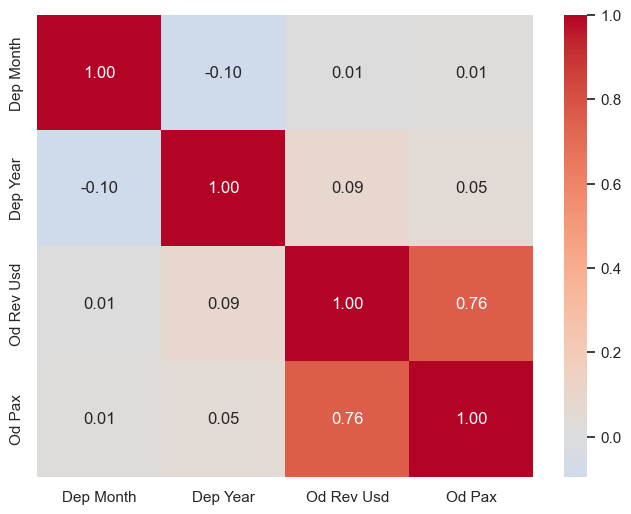

In [42]:
corr = df[num_cols + [target]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

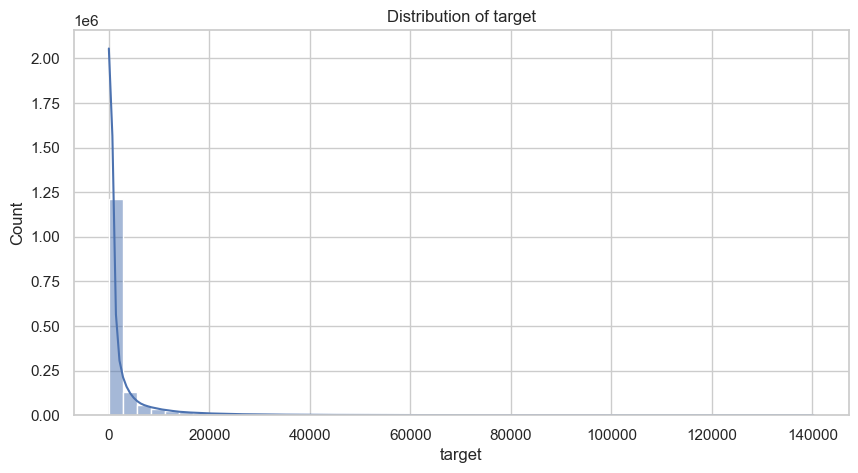

In [ ]:
sns.histplot(df[target], bins=50, kde=True)
plt.title('Distribution of Od Pax')
plt.xlabel('Od Pax')
plt.ylabel('Count')
plt.show()